In [ ]:
from pathlib import Path
import json, urllib.request, hashlib, random, re, math, zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = True
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/DS480_AI_Detector')
else:
    ROOT = Path.cwd() / 'DS480_AI_Detector'
for folder in ['data', 'results', 'texts']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
RESULTS_PATH = ROOT / 'results/manual_results.csv'
print('Saved Location:', ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved Location: /content/drive/MyDrive/DS480_AI_Detector


In [ ]:
BASE = 'https://raw.githubusercontent.com/Weixin-Liang/ChatGPT-Detector-Bias/main/Data_and_Results/Human_Data/'
GROUPS = [('TOEFL', 'TOEFL_real_91', 91), ('US_student', 'HewlettStudentEssay_real_88', 88)]
rows, manifest = [], []
for group, folder, expected in GROUPS:
    payloads = {}
    for filename in ['data.json', 'GPTZero.json']:
        path = ROOT / 'data' / f'{group}_{filename}'
        url = BASE + folder + '/' + filename
        if not path.exists():
            with urllib.request.urlopen(url, timeout=60) as response:
                raw = response.read()
            json.loads(raw)  # validate before saving
            path.write_bytes(raw)
        raw = path.read_bytes()
        payloads[filename] = json.loads(raw)
        manifest.append({'file':path.name, 'url':url, 'sha256':hashlib.sha256(raw).hexdigest()})
    originals, old = payloads['data.json'], payloads['GPTZero.json']
    assert len(originals) == expected, (group, len(originals))
    old_by_text = {}
    for item in old:
        text = item['document']
        old_by_text.setdefault(text, []).append(item)
    for index, item in enumerate(originals, 1):
        text = item['document']
        assert isinstance(text, str) and text.strip()
        candidates = old_by_text.get(text, [])
        if index <= len(old) and old[index-1]['document'] == text:
            historic = old[index-1]  # verify text, not order alone
        elif len(candidates) == 1:
            historic = candidates[0]
        else:
            raise ValueError(f'Ambiguous historical match: {group}, {index}')
        row = {'essay_id':f'{group}_{index:03d}', 'group':group, 'text':text,
               'word_count':len(text.split()), 'text_sha256':hashlib.sha256(text.encode()).hexdigest()}
        for key, value in historic.items():
            if key != 'document':
                row['old_' + key] = value
        rows.append(row)
corpus = pd.DataFrame(rows)
assert corpus.essay_id.is_unique and len(corpus) == 179
randomizer = random.Random(480)
pilot_ids = set()
for group, _, _ in GROUPS:
    pilot_ids.update(randomizer.sample(corpus.loc[corpus.group.eq(group), 'essay_id'].tolist(), 10))
corpus['duplicate_within_group'] = corpus.duplicated(['group','text'])
corpus['pilot'] = corpus.essay_id.isin(pilot_ids)
corpus.to_csv(ROOT / 'data/corpus.csv', index=False)
(ROOT / 'data/source_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
for row in corpus.itertuples():
    (ROOT / 'texts' / f'{row.essay_id}.txt').write_text(row.text, encoding='utf-8')
print(corpus.groupby('group').agg(essays=('essay_id','size'), words=('word_count','sum'), pilot=('pilot','sum')))
print('Total word count across all 179 essays:', int(corpus.word_count.sum()))
print('Duplicate text count:', int(corpus.text.duplicated().sum()))

            essays  words  pilot
group                           
TOEFL           91   9748     10
US_student      88  33262     10
Total word count across all 179 essays: 43010
Duplicate text count: 1


In [ ]:
import pandas as pd

RESULTS_PATH = ROOT / "results" / "manual_results.csv"

FIELDS = [
    "essay_id",
    "status",
    "label",
    "raw_verdict",
    "displayed_score_0_100",
    "score_field_name",
    "scan_date",
    "model_version",
    "evidence_file",
    "notes",
]

if RESULTS_PATH.exists():
    results = pd.read_csv(
        RESULTS_PATH,
        dtype=str,
        keep_default_na=False,
    )

    missing_columns = set(FIELDS) - set(results.columns)

    if missing_columns:
        raise ValueError(
            f"Missing columns in the existing results file: {missing_columns}"
        )

    if not results["essay_id"].is_unique:
        raise ValueError("Duplicate essay IDs found in the results file.")

    if not set(results["essay_id"]).issubset(set(corpus["essay_id"])):
        raise ValueError("Unknown essay IDs found in the results file.")

    print("Existing results loaded.")
else:
    results = pd.DataFrame(columns=FIELDS)
    print("New results table prepared.")

print(f"Recorded essays: {len(results)} / {len(corpus)}")

New results table prepared.
Recorded essays: 0 / 179


In [ ]:
import ipywidgets as widgets
from IPython.display import display
from datetime import datetime
from zoneinfo import ZoneInfo
import math
import html

pilot_only = widgets.Checkbox(
    value=True,
    description="Pilot only",
)

essay_selector = widgets.Dropdown(
    description="Essay:",
    layout=widgets.Layout(width="95%"),
)

essay_info = widgets.HTML()

essay_text = widgets.Textarea(
    description="Text:",
    layout=widgets.Layout(width="100%", height="300px"),
)

label_input = widgets.Dropdown(
    options=[
        "",
        "Human",
        "AI",
        "Mixed",
        "AI-edited",
        "Other",
        "Unavailable",
    ],
    description="Label:",
)

verdict_input = widgets.Text(
    description="Exact verdict:",
    layout=widgets.Layout(width="95%"),
)

score_input = widgets.Text(
    description="Score 0–100:",
)

score_name_input = widgets.Text(
    description="Score field:",
    layout=widgets.Layout(width="95%"),
)

date_input = widgets.Text(
    value=datetime.now(
        ZoneInfo("America/New_York")
    ).date().isoformat(),
    description="Scan date:",
)

version_input = widgets.Text(
    value="not shown",
    description="Model version:",
)

evidence_input = widgets.Text(
    description="Evidence file:",
    layout=widgets.Layout(width="95%"),
)

notes_input = widgets.Textarea(
    description="Notes:",
    layout=widgets.Layout(width="95%", height="70px"),
)

save_button = widgets.Button(
    description="Save + Next",
    button_style="success",
)

message = widgets.HTML()


def load_essay(change=None):
    essay_id = essay_selector.value

    if essay_id is None:
        return

    row = corpus.set_index("essay_id").loc[essay_id]

    essay_info.value = (
        f"<b>{essay_id}</b> | "
        f"{row['group']} | "
        f"{row['word_count']} words"
    )

    essay_text.value = row["text"]

    existing = results.loc[
        results["essay_id"].eq(essay_id)
    ]

    record = (
        existing.iloc[0].to_dict()
        if not existing.empty
        else {}
    )

    label_input.value = record.get("label", "")
    verdict_input.value = record.get("raw_verdict", "")
    score_input.value = record.get(
        "displayed_score_0_100", ""
    )
    score_name_input.value = record.get(
        "score_field_name", ""
    )
    date_input.value = record.get(
        "scan_date",
        datetime.now(
            ZoneInfo("America/New_York")
        ).date().isoformat(),
    )
    version_input.value = record.get(
        "model_version", "not shown"
    )
    evidence_input.value = record.get(
        "evidence_file", ""
    )
    notes_input.value = record.get("notes", "")


def refresh_list(change=None):
    selected = (
        corpus.loc[corpus["pilot"]]
        if pilot_only.value
        else corpus
    )

    essay_selector.options = selected["essay_id"].tolist()

    pending = selected.loc[
        ~selected["essay_id"].isin(results["essay_id"]),
        "essay_id",
    ]

    if not pending.empty:
        essay_selector.value = pending.iloc[0]

    load_essay()

    if pending.empty:
        message.value = (
            "<b>All essays in this selection have records.</b>"
        )


def save_result(button):
    global results

    try:
        essay_id = essay_selector.value

        if essay_id is None or not label_input.value:
            raise ValueError("Select a label.")

        if not verdict_input.value.strip():
            raise ValueError(
                "Enter the exact verdict or scan failure reason."
            )

        datetime.strptime(
            date_input.value.strip(), "%Y-%m-%d"
        )

        if score_input.value.strip():
            score = float(score_input.value)

            if not math.isfinite(score) or not 0 <= score <= 100:
                raise ValueError(
                    "Score must be between 0 and 100."
                )

            if not score_name_input.value.strip():
                raise ValueError(
                    "Enter the score field name."
                )

        record = {
            "essay_id": essay_id,
            "status": (
                "unavailable"
                if label_input.value == "Unavailable"
                else "scanned"
            ),
            "label": label_input.value,
            "raw_verdict": verdict_input.value.strip(),
            "displayed_score_0_100": score_input.value.strip(),
            "score_field_name": score_name_input.value.strip(),
            "scan_date": date_input.value.strip(),
            "model_version": version_input.value.strip(),
            "evidence_file": evidence_input.value.strip(),
            "notes": notes_input.value.strip(),
        }

        updated = pd.concat(
            [
                results.loc[
                    ~results["essay_id"].eq(essay_id)
                ],
                pd.DataFrame([record]),
            ],
            ignore_index=True,
        )

        if RESULTS_PATH.exists():
            backup_path = RESULTS_PATH.with_name(
                "manual_results_previous.csv"
            )
            backup_path.write_bytes(
                RESULTS_PATH.read_bytes()
            )

        temporary_path = RESULTS_PATH.with_suffix(".tmp")
        updated.to_csv(temporary_path, index=False)
        temporary_path.replace(RESULTS_PATH)

        results = updated

        message.value = (
            f"<b>Saved: {essay_id}</b> | "
            f"{len(results)} records total"
        )

        refresh_list()

    except Exception as error:
        message.value = (
            "<b>Check input:</b> "
            + html.escape(str(error))
        )


essay_selector.observe(load_essay, names="value")
pilot_only.observe(refresh_list, names="value")
save_button.on_click(save_result)

refresh_list()

display(
    widgets.VBox(
        [
            pilot_only,
            essay_selector,
            essay_info,
            essay_text,
            label_input,
            verdict_input,
            score_input,
            score_name_input,
            date_input,
            version_input,
            evidence_input,
            notes_input,
            save_button,
            message,
        ]
    )
)

In [ ]:
import pandas as pd
from IPython.display import display

saved_results = pd.read_csv(
    RESULTS_PATH,
    dtype=str,
    keep_default_na=False,
)

if not saved_results["essay_id"].is_unique:
    raise ValueError("Duplicate essay IDs found in the results file.")

pilot = corpus.loc[
    corpus["pilot"],
    ["essay_id", "group", "text"],
].copy()

pilot_results = pilot.merge(
    saved_results,
    on="essay_id",
    how="left",
    validate="one_to_one",
)

missing_ids = pilot_results.loc[
    pilot_results["status"].isna(),
    "essay_id",
].tolist()

print(f"Planned pilot essays: {len(pilot)}")
print(f"Recorded pilot essays: {pilot_results['status'].notna().sum()}")
print(f"Missing pilot essays: {len(missing_ids)}")

if missing_ids:
    print("Missing essay IDs:", missing_ids)

pilot_results["recorded_label"] = (
    pilot_results["label"]
    .fillna("Unrecorded")
    .replace("", "Needs review")
)

print("\nPilot label distribution:")
display(
    pd.crosstab(
        pilot_results["group"],
        pilot_results["recorded_label"],
    )
)

print("\nPilot scan status:")
display(
    pd.crosstab(
        pilot_results["group"],
        pilot_results["status"].fillna("Unrecorded"),
    )
)

duplicate_count = pilot_results.duplicated(
    subset=["group", "text"]
).sum()

print(f"\nDuplicate texts within pilot groups: {duplicate_count}")

print("\nRecorded details:")
display(
    pilot_results[
        [
            "essay_id",
            "group",
            "label",
            "displayed_score_0_100",
            "model_version",
        ]
    ]
)

Planned pilot essays: 20
Recorded pilot essays: 20
Missing pilot essays: 0

Pilot label distribution:


recorded_label,Human
group,
TOEFL,10
US_student,10



Pilot scan status:


status,scanned
group,
TOEFL,10
US_student,10



Duplicate texts within pilot groups: 0

Recorded details:


,essay_id,group,label,displayed_score_0_100,model_version
0,TOEFL_012,TOEFL,Human,0,5.0b
1,TOEFL_027,TOEFL,Human,0,5.0b
2,TOEFL_038,TOEFL,Human,0,5.0b
3,TOEFL_040,TOEFL,Human,0,5.0b
4,TOEFL_051,TOEFL,Human,0,5.0b
5,TOEFL_059,TOEFL,Human,0,5.0b
6,TOEFL_067,TOEFL,Human,0,5.0b
7,TOEFL_073,TOEFL,Human,0,5.0b
8,TOEFL_086,TOEFL,Human,0,5.0b
9,TOEFL_088,TOEFL,Human,0,5.0b


In [ ]:
import math
import pandas as pd
from IPython.display import display

if pilot_results["status"].isna().any():
    raise ValueError("Some pilot essays have not been recorded.")

if not pilot_results["status"].eq("scanned").all():
    raise ValueError("Review unavailable or incomplete scans first.")

valid_labels = {"Human", "AI", "Mixed", "AI-edited"}

if not pilot_results["label"].isin(valid_labels).all():
    raise ValueError("Review unrecognized labels before analysis.")

analysis_data = pilot_results.drop_duplicates(
    subset=["group", "text"]
).copy()


def wilson_interval(k, n):
    z = 1.959963984540054
    p = k / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    margin = (
        z
        * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
        / denominator
    )
    return max(0.0, center - margin), min(1.0, center + margin)


summary_rows = []

for group, data in analysis_data.groupby("group"):
    n = len(data)
    k = int(data["label"].eq("AI").sum())
    lower, upper = wilson_interval(k, n)

    summary_rows.append({
        "group": group,
        "evaluated_n": n,
        "AI_false_positives": k,
        "FPR_percent": 100 * k / n,
        "CI_95_lower_percent": 100 * lower,
        "CI_95_upper_percent": 100 * upper,
        "Mixed_or_AI_edited_n": int(
            data["label"].isin(["Mixed", "AI-edited"]).sum()
        ),
    })

pilot_summary = pd.DataFrame(summary_rows)

print("Pilot results: AI-only false-positive rates")
display(pilot_summary.round(2))

output_path = ROOT / "results" / "pilot_summary.csv"
pilot_summary.to_csv(output_path, index=False)

print("Summary saved to:", output_path)

Pilot results: AI-only false-positive rates


,group,evaluated_n,AI_false_positives,FPR_percent,CI_95_lower_percent,CI_95_upper_percent,Mixed_or_AI_edited_n
0,TOEFL,10,0,0.0,0.0,27.75,0
1,US_student,10,0,0.0,0.0,27.75,0


Summary saved to: /content/drive/MyDrive/DS480_AI_Detector/results/pilot_summary.csv


In [ ]:
import random
import pandas as pd

SELECTION_PATH = ROOT / "data" / "evaluation_selection_60.csv"
DEFAULT_MODEL_VERSION = "5.0b"

# Reload saved manual results.
results = pd.read_csv(
    RESULTS_PATH,
    dtype=str,
    keep_default_na=False,
)

# Reuse the same selection if this cell is run again.
if SELECTION_PATH.exists():
    selection = pd.read_csv(
        SELECTION_PATH,
        dtype=str,
        keep_default_na=False,
    )

else:
    rng = random.Random(48040)
    selected_ids = []

    for group in ["TOEFL", "US_student"]:
        group_data = corpus.loc[
            corpus["group"].eq(group)
        ].copy()

        original_pilot = group_data.loc[
            group_data["pilot"]
        ].copy()

        if len(original_pilot) != 10:
            raise ValueError(
                f"Expected 10 original pilot essays in {group}."
            )

        if original_pilot["text"].duplicated().any():
            raise ValueError(
                f"Duplicate texts found in the original pilot: {group}."
            )

        candidates = group_data.loc[
            ~group_data["text"].isin(original_pilot["text"])
        ].drop_duplicates(subset=["text"])

        additional_ids = rng.sample(
            candidates["essay_id"].tolist(),
            20,
        )

        selected_ids.extend(
            original_pilot["essay_id"].tolist()
            + additional_ids
        )

    selection = corpus.loc[
        corpus["essay_id"].isin(selected_ids),
        ["essay_id", "group"],
    ].copy()

    selection["stage"] = selection["essay_id"].map(
        lambda essay_id: (
            "original_pilot"
            if essay_id in set(
                corpus.loc[corpus["pilot"], "essay_id"]
            )
            else "additional"
        )
    )

    selection.to_csv(SELECTION_PATH, index=False)

# Validate the saved selection.
if not selection["essay_id"].is_unique:
    raise ValueError("Duplicate essay IDs in the selection.")

if not set(selection["essay_id"]).issubset(
    set(corpus["essay_id"])
):
    raise ValueError("Unknown essay IDs in the selection.")

evaluation_data = corpus.merge(
    selection[["essay_id", "stage"]],
    on="essay_id",
    how="inner",
    validate="one_to_one",
)

counts = evaluation_data.groupby("group").size()

if counts.to_dict() != {"TOEFL": 30, "US_student": 30}:
    raise ValueError("The selection must contain 30 essays per group.")

if evaluation_data.duplicated(["group", "text"]).any():
    raise ValueError("Duplicate texts within evaluation groups.")

# Limit the existing form to the selected 60 essays.
def refresh_list(change=None):
    essay_selector.options = (
        evaluation_data["essay_id"].tolist()
    )

    pending = evaluation_data.loc[
        ~evaluation_data["essay_id"].isin(
            results["essay_id"]
        ),
        "essay_id",
    ]

    if not pending.empty:
        essay_selector.value = pending.iloc[0]

    load_essay()
    set_default_model_version()

    if pending.empty:
        message.value = (
            "<b>All 60 selected essays have records. "
            "Review any unavailable or uncertain results.</b>"
        )


def set_default_model_version(change=None):
    existing = results.loc[
        results["essay_id"].eq(essay_selector.value)
    ]

    if existing.empty:
        version_input.value = DEFAULT_MODEL_VERSION
    elif not existing.iloc[0]["model_version"].strip():
        version_input.value = DEFAULT_MODEL_VERSION


# Replace the old pilot filter behavior.
pilot_only.unobserve_all(name="value")
pilot_only.description = "60-essay selection"
pilot_only.value = True
pilot_only.disabled = True

# Avoid duplicate callbacks when rerunning this cell.
if "_model_default_callback" in globals():
    try:
        essay_selector.unobserve(
            _model_default_callback,
            names="value",
        )
    except ValueError:
        pass

_model_default_callback = set_default_model_version

essay_selector.observe(
    _model_default_callback,
    names="value",
)

refresh_list()

progress = evaluation_data[
    ["essay_id", "group"]
].merge(
    results[["essay_id", "status"]],
    on="essay_id",
    how="left",
    validate="one_to_one",
)

progress["has_record"] = progress["status"].notna()

print("Evaluation progress:")
display(
    progress.groupby("group").agg(
        selected=("essay_id", "size"),
        recorded=("has_record", "sum"),
    )
)

print(
    "Essays without records:",
    int(progress["status"].isna().sum()),
)
print("Default model version:", DEFAULT_MODEL_VERSION)
print("Selection saved to:", SELECTION_PATH)

Evaluation progress:


,selected,recorded
group,,
TOEFL,30,12
US_student,30,10


Essays without records: 38
Default model version: 5.0b
Selection saved to: /content/drive/MyDrive/DS480_AI_Detector/data/evaluation_selection_60.csv


In [13]:
import pandas as pd
from IPython.display import display

selection = pd.read_csv(
    ROOT / "data" / "evaluation_selection_60.csv",
    dtype=str,
    keep_default_na=False,
)

saved_results = pd.read_csv(
    RESULTS_PATH,
    dtype=str,
    keep_default_na=False,
)

if not selection["essay_id"].is_unique:
    raise ValueError("Duplicate essay IDs in the selection.")

if not saved_results["essay_id"].is_unique:
    raise ValueError("Duplicate essay IDs in the results.")

final_results = selection.merge(
    saved_results,
    on="essay_id",
    how="left",
    validate="one_to_one",
)

final_results["recorded"] = final_results["status"].notna()

print("Completion by group:")
display(
    final_results.groupby("group").agg(
        selected=("essay_id", "size"),
        recorded=("recorded", "sum"),
    )
)

print("\nRecorded labels:")
display(
    pd.crosstab(
        final_results["group"],
        final_results["label"].fillna("Unrecorded"),
    )
)

print("\nScan status:")
display(
    pd.crosstab(
        final_results["group"],
        final_results["status"].fillna("Unrecorded"),
    )
)

missing_ids = final_results.loc[
    ~final_results["recorded"], "essay_id"
].tolist()

print("\nMissing essay IDs:", missing_ids)

missing_evidence = []
for row in final_results.itertuples():
    evidence = (
        row.evidence_file
        if isinstance(row.evidence_file, str)
        else ""
    )

    if not evidence.strip():
        missing_evidence.append(row.essay_id)
    elif not (ROOT / "results" / evidence).is_file():
        missing_evidence.append(row.essay_id)

print("\nMissing evidence files:", missing_evidence)

print("\nModel versions:")
display(
    final_results["model_version"]
    .fillna("Unrecorded")
    .value_counts()
)

Completion by group:


,selected,recorded
group,,
TOEFL,30,30
US_student,30,30



Recorded labels:


label,Human
group,
TOEFL,30
US_student,30



Scan status:


status,scanned
group,
TOEFL,30
US_student,30



Missing essay IDs: []

Missing evidence files: []

Model versions:


,count
model_version,
5.0b,60


Final results:


,group,evaluated_n,AI_false_positives,FPR_percent,CI_95_lower_percent,CI_95_upper_percent,Mixed_or_AI_edited_n
0,TOEFL,30,0,0.0,0.0,11.35,0
1,US_student,30,0,0.0,0.0,11.35,0


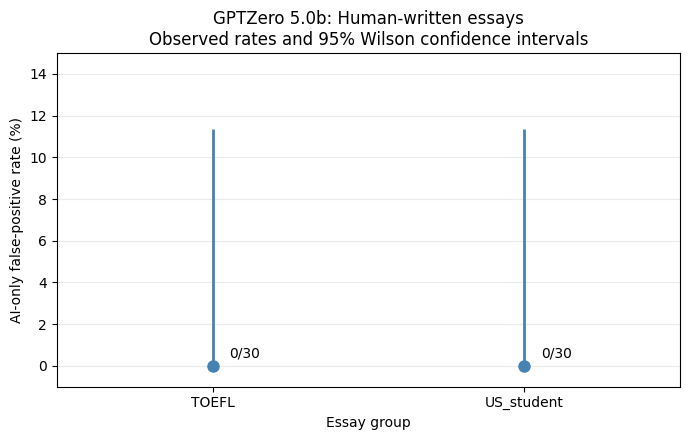

Saved: final_summary_60.csv
Saved: final_results_60.csv
Saved: final_fpr_60.png


In [14]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Reload saved results and selection.
selection = pd.read_csv(
    ROOT / "data" / "evaluation_selection_60.csv",
    dtype=str,
    keep_default_na=False,
)

saved_results = pd.read_csv(
    RESULTS_PATH,
    dtype=str,
    keep_default_na=False,
)

analysis_data = selection.merge(
    saved_results,
    on="essay_id",
    how="left",
    validate="one_to_one",
).merge(
    corpus[["essay_id", "text", "word_count"]],
    on="essay_id",
    how="left",
    validate="one_to_one",
)

if len(analysis_data) != 60:
    raise ValueError("Expected 60 selected essays.")

if not analysis_data["status"].eq("scanned").all():
    raise ValueError("Some selected essays are not scanned.")

valid_labels = {"Human", "AI", "Mixed", "AI-edited"}

if not analysis_data["label"].isin(valid_labels).all():
    raise ValueError("Review labels before analysis.")

if analysis_data["text"].isna().any():
    raise ValueError("Some original texts are missing.")

if analysis_data.duplicated(["group", "text"]).any():
    raise ValueError("Duplicate texts found within groups.")

if analysis_data.groupby("group").size().to_dict() != {
    "TOEFL": 30,
    "US_student": 30,
}:
    raise ValueError("Expected 30 essays per group.")


def wilson_interval(k, n):
    z = 1.959963984540054
    p = k / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    margin = (
        z
        * math.sqrt(
            p * (1 - p) / n + z**2 / (4 * n**2)
        )
        / denominator
    )
    return max(0.0, center - margin), min(1.0, center + margin)


summary_rows = []

for group, data in analysis_data.groupby("group"):
    n = len(data)
    k = int(data["label"].eq("AI").sum())
    lower, upper = wilson_interval(k, n)

    summary_rows.append({
        "group": group,
        "evaluated_n": n,
        "AI_false_positives": k,
        "FPR_percent": 100 * k / n,
        "CI_95_lower_percent": 100 * lower,
        "CI_95_upper_percent": 100 * upper,
        "Mixed_or_AI_edited_n": int(
            data["label"].isin(
                ["Mixed", "AI-edited"]
            ).sum()
        ),
    })

final_summary = pd.DataFrame(summary_rows)

final_summary.to_csv(
    ROOT / "results" / "final_summary_60.csv",
    index=False,
)

analysis_data.to_csv(
    ROOT / "results" / "final_results_60.csv",
    index=False,
)

print("Final results:")
display(final_summary.round(2))

# Plot observed rates with 95% Wilson intervals.
fig, ax = plt.subplots(figsize=(7, 4.5))

for position, row in enumerate(
    final_summary.itertuples(index=False)
):
    ax.vlines(
        position,
        row.CI_95_lower_percent,
        row.CI_95_upper_percent,
        color="steelblue",
        linewidth=2,
    )
    ax.plot(
        position,
        row.FPR_percent,
        "o",
        color="steelblue",
        markersize=8,
    )
    ax.annotate(
        f"{row.AI_false_positives}/{row.evaluated_n}",
        (position, row.FPR_percent),
        xytext=(12, 6),
        textcoords="offset points",
    )

ax.set_xticks(
    range(len(final_summary)),
    final_summary["group"],
)
ax.set_xlim(-0.5, len(final_summary) - 0.5)
ax.set_ylim(
    -1,
    max(
        15,
        final_summary["CI_95_upper_percent"].max() + 3,
    ),
)
ax.set_ylabel("AI-only false-positive rate (%)")
ax.set_xlabel("Essay group")
ax.set_title(
    "GPTZero 5.0b: Human-written essays\n"
    "Observed rates and 95% Wilson confidence intervals"
)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    ROOT / "results" / "final_fpr_60.png",
    dpi=300,
)
plt.show()

print("Saved: final_summary_60.csv")
print("Saved: final_results_60.csv")
print("Saved: final_fpr_60.png")

In [15]:
# Identify recorded warnings separately from calculated word counts.
analysis_data["short_text_warning"] = (
    analysis_data["notes"]
    .fillna("")
    .str.contains("under 100 words", case=False, regex=False)
)

analysis_data["below_100_words"] = (
    analysis_data["word_count"] < 100
)

print("Text length and recorded warnings:")
display(
    analysis_data.groupby("group").agg(
        essays=("essay_id", "size"),
        minimum_words=("word_count", "min"),
        median_words=("word_count", "median"),
        maximum_words=("word_count", "max"),
        below_100_words=("below_100_words", "sum"),
        recorded_short_text_warnings=("short_text_warning", "sum"),
    )
)

print("\nResults excluding essays with recorded short-text warnings:")

without_warnings = analysis_data.loc[
    ~analysis_data["short_text_warning"]
]

sensitivity_rows = []

for group, data in without_warnings.groupby("group"):
    n = len(data)
    k = int(data["label"].eq("AI").sum())
    lower, upper = wilson_interval(k, n)

    sensitivity_rows.append({
        "group": group,
        "evaluated_n": n,
        "AI_false_positives": k,
        "FPR_percent": 100 * k / n,
        "CI_95_lower_percent": 100 * lower,
        "CI_95_upper_percent": 100 * upper,
    })

sensitivity_summary = pd.DataFrame(sensitivity_rows)
display(sensitivity_summary.round(2))

sensitivity_summary.to_csv(
    ROOT / "results" / "sensitivity_without_warnings.csv",
    index=False,
)

analysis_data.to_csv(
    ROOT / "results" / "final_results_60.csv",
    index=False,
)

Text length and recorded warnings:


,essays,minimum_words,median_words,maximum_words,below_100_words,recorded_short_text_warnings
group,,,,,,
TOEFL,30,62,104.0,144,8,8
US_student,30,176,400.5,677,0,0



Results excluding essays with recorded short-text warnings:


,group,evaluated_n,AI_false_positives,FPR_percent,CI_95_lower_percent,CI_95_upper_percent
0,TOEFL,22,0,0.0,0.0,14.87
1,US_student,30,0,0.0,0.0,11.35


In [16]:
historical_columns = [
    column
    for column in corpus.columns
    if column.startswith("old_")
]

print("Available historical fields:")
print(historical_columns)

print("\nHistorical field summaries:")

for column in historical_columns:
    values = pd.to_numeric(
        corpus[column],
        errors="coerce",
    )

    print(f"\nField: {column}")

    if values.notna().any():
        display(
            corpus.assign(
                historical_value=values
            ).groupby("group")[
                "historical_value"
            ].agg(["count", "min", "median", "max"])
        )
    else:
        print("Non-numeric field.")
        display(corpus[column].value_counts().head(10))

Available historical fields:
['old_score', 'old_perplexity', 'old_overall_burstiness', 'old_average_generated_prob', 'old_completely_generated_prob']

Historical field summaries:

Field: old_score


,count,min,median,max
group,,,,
TOEFL,91,3.002407e-07,5.710657e-01,0.918775
US_student,88,2.284525e-36,7.952399e-17,0.193205



Field: old_perplexity


,count,min,median,max
group,,,,
TOEFL,91,22.00000,42.166667,197.666667
US_student,88,56.37037,170.676319,1940.000000



Field: old_overall_burstiness


,count,min,median,max
group,,,,
TOEFL,91,2.061553,24.635679,353.175110
US_student,88,36.942936,205.046715,8671.168945



Field: old_average_generated_prob


,count,min,median,max
group,,,,
TOEFL,91,0.0,0.75,1.000000
US_student,88,0.0,0.00,0.757576



Field: old_completely_generated_prob


,count,min,median,max
group,,,,
TOEFL,91,3.002407e-07,5.710657e-01,0.918775
US_student,88,2.284525e-36,7.952399e-17,0.193205


In [17]:
import numpy as np
import pandas as pd
from IPython.display import display

# Match historical scores to the same 60 evaluated essays.
historical_60 = analysis_data[
    ["essay_id", "group", "label"]
].merge(
    corpus[
        [
            "essay_id",
            "old_score",
            "old_completely_generated_prob",
        ]
    ],
    on="essay_id",
    how="left",
    validate="one_to_one",
)

for column in [
    "old_score",
    "old_completely_generated_prob",
]:
    historical_60[column] = pd.to_numeric(
        historical_60[column],
        errors="raise",
    )

if historical_60[
    ["old_score", "old_completely_generated_prob"]
].isna().any().any():
    raise ValueError("Historical scores are missing.")

print("Historical scores for the same 60 essays:")
display(
    historical_60.groupby("group")["old_score"]
    .agg(["count", "min", "median", "max"])
    .round(6)
)

print(
    "Historical score fields match:",
    np.allclose(
        historical_60["old_score"],
        historical_60["old_completely_generated_prob"],
    ),
)

# These are assumed thresholds, not verified historical rules.
threshold_rows = []

for threshold in [0.3, 0.5, 0.7, 0.9]:
    for group, data in historical_60.groupby("group"):
        flagged = int(
            data["old_score"].ge(threshold).sum()
        )

        threshold_rows.append({
            "assumed_threshold": threshold,
            "group": group,
            "evaluated_n": len(data),
            "historical_scores_at_or_above_threshold": flagged,
            "percentage_at_or_above_threshold": (
                100 * flagged / len(data)
            ),
        })

threshold_sensitivity = pd.DataFrame(threshold_rows)

print("\nExploratory threshold sensitivity:")
print(
    "These thresholds do not reproduce a verified "
    "historical classification rule."
)
display(threshold_sensitivity.round(2))

historical_60.to_csv(
    ROOT / "results" / "historical_scores_same_60.csv",
    index=False,
)

threshold_sensitivity.to_csv(
    ROOT / "results" / "historical_threshold_sensitivity.csv",
    index=False,
)

Historical scores for the same 60 essays:


,count,min,median,max
group,,,,
TOEFL,30,0.0,0.072194,0.910342
US_student,30,0.0,0.000000,0.193205


Historical score fields match: True

Exploratory threshold sensitivity:
These thresholds do not reproduce a verified historical classification rule.


,assumed_threshold,group,evaluated_n,historical_scores_at_or_above_threshold,percentage_at_or_above_threshold
0,0.3,TOEFL,30,13,43.33
1,0.3,US_student,30,0,0.00
2,0.5,TOEFL,30,13,43.33
3,0.5,US_student,30,0,0.00
4,0.7,TOEFL,30,12,40.00
5,0.7,US_student,30,0,0.00
6,0.9,TOEFL,30,3,10.00
7,0.9,US_student,30,0,0.00
